In [1]:
from pathlib import Path
import requests

from openmm import *
from openmm.app import *
from openmm import unit
from openmm.unit import *

import mdtraj as md

import pdbfixer
from pdbfixer import PDBFixer

from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import AllChem

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nglview as nv

import MDAnalysis as mda
from MDAnalysis.analysis import rms, diffusionmap, align
from MDAnalysis.analysis.distances import dist
from MDAnalysis.analysis.hydrogenbonds.hbond_analysis import HydrogenBondAnalysis as HBA

In [2]:
HERE = Path(_dh[-1])
DATA = HERE / "data"

## Starting structure: the docked complex from step 7

An MD simulation needs the ligand already placed in the binding site, so this notebook starts
from the **best docked pose of our top hit** produced in step 7, not from a co-crystallised ligand.

- **Protein:** the DRD2 receptor the ligand was docked into (`drd2_repaired.pdb`, prepared from PDB 6CM4).
  It has to be this exact structure, because the pose coordinates only match this receptor.
- **Ligand:** pose 1 from `docked_poses.sdf` (Vina score -10.32 kcal/mol).

In [3]:
# Our docked complex: DRD2 (PDB 6CM4, inactive state) with the allosteric Na+ ion
# and our top hit s_2230__9292524__16949512 (residue LIG) in the binding pocket
COMPLEX_FILE = HERE.parent / "Naked_6CM4_NA_lig1.mmcif"

# Top hit with the basic piperazine nitrogen protonated (pH 7.4), the partner of Asp114
LIGAND_SMILES = "CC1=C(C(=O)N2CCCCC2=N1)CC[NH+]3CCN(CC3)C4=C(C(=CC=C4)F)F"

if not COMPLEX_FILE.is_file():
    raise FileNotFoundError(f"{COMPLEX_FILE} is missing.")
print(f"Using the docked complex {COMPLEX_FILE.name}")

Using the docked complex Naked_6CM4_NA_lig1.mmcif


## Prepare the protein

In [4]:
def prepare_protein(mmcif_file, ligand_resname="LIG", icl2_loop=("MET", "LEU", "TYR", "ASN"), ph=7.4):
    """
    Use pdbfixer to prepare our DRD2 receptor (6CM4, inactive state) from the docked complex.

    Compared to the talktorial version, this keeps the allosteric Na+ ion, removes the
    T4 lysozyme fusion fragments, starts a new chain at the ICL3 gap and rebuilds the
    four missing ICL2 residues (140-143).

    Parameters
    ----------
    mmcif_file: pathlib.Path or str
        mmCIF file containing the receptor (and the docked ligand).
    ligand_resname: str
        Residue name of the docked ligand, which is removed here and prepared separately.
    icl2_loop: tuple of str
        Residues missing between Pro139 and Thr144 (M-L-Y-N in UniProt P14416).
    ph: float, optional
        pH value used to determine protonation state of residues

    Returns
    -------
    fixer: pdbfixer.pdbfixer.PDBFixer
        Prepared protein system.
    """
    with open(mmcif_file) as f:  # the .mmcif extension is not recognised, so pass it as PDBx
        fixer = pdbfixer.PDBFixer(pdbxfile=f)

    # Rebuild the topology without the ligand, waters and T4L fragments (resid >= 1000), starting a
    # new chain wherever the residue numbering jumps. In mmCIF there are no TER records,
    # so otherwise OpenMM would bond the residues on both sides of a gap together.
    topology = Topology()
    positions = []
    chain, previous = None, None
    for residue in fixer.topology.residues():
        if residue.name in ("HOH", ligand_resname) or (residue.name != "NA" and int(residue.id) >= 1000):
            continue
        resid = int(residue.id)
        is_icl2_gap = previous == 139 and resid == 144  # rebuilt below, so stays in the same chain
        if chain is None or residue.name == "NA" or (previous is not None and resid != previous + 1 and not is_icl2_gap):
            chain = topology.addChain()
        new_residue = topology.addResidue(residue.name, chain, residue.id)
        for atom in residue.atoms():
            topology.addAtom(atom.name, atom.element, new_residue)
            positions.append(fixer.positions[atom.index])
        previous = resid
    topology.createStandardBonds()
    topology.createDisulfideBonds(positions)
    fixer.topology, fixer.positions = topology, positions

    # Rebuild ICL2: insert the missing residues before Thr144 in the first chain
    first_chain = list(fixer.topology.chains())[0]
    thr144 = [r.id for r in first_chain.residues()].index("144")
    fixer.missingResidues = {(first_chain.index, thr144): list(icl2_loop)}

    fixer.findNonstandardResidues()  # find non-standard residue
    fixer.replaceNonstandardResidues()  # replace non-standard residues with standard one
    fixer.findMissingAtoms()  # find missing heavy atoms (e.g. the truncated His442 side chain)
    fixer.addMissingAtoms()  # add missing atoms and residues
    fixer.addMissingHydrogens(ph)  # add missing hydrogens
    return fixer

In [5]:
# Prepare our receptor (keeps Na+, removes ligand/T4L fragments, rebuilds ICL2, adds hydrogens)
prepared_protein = prepare_protein(COMPLEX_FILE)
print("Successfully prepared protein:", prepared_protein.topology.getNumAtoms(), "atoms")

Successfully prepared protein: 4375 atoms


## Prepare the ligand

The docked pose already carries 3D coordinates and hydrogens, so no new conformer is generated:
re-embedding would throw away the binding pose. Every ligand atom is given the residue name
**`LIG`**, which is how the ligand is selected in the analysis further down.

Docked top hit: Cc1nc2n(c(=O)c1CC[NH+]1CCN(c3cccc(F)c3F)CC1)CCCC2 | net charge: 1


[14:03:56] WARNING: More than one matching pattern found - picking one



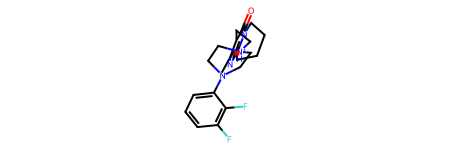

In [6]:
# Take the docked top hit (residue LIG) out of the complex, keeping its pose and atom names
complex_structure = PDBxFile(str(COMPLEX_FILE))
ligand_atoms = [atom for atom in complex_structure.topology.atoms() if atom.residue.name == "LIG"]
pdb_block = "\n".join(
    "HETATM{:5d} {:<4s} LIG L   1    {:8.3f}{:8.3f}{:8.3f}  1.00  0.00          {:>2s}".format(
        i + 1, atom.name, *complex_structure.positions[atom.index].value_in_unit(angstrom), atom.element.symbol
    )
    for i, atom in enumerate(ligand_atoms)
)
pose = Chem.MolFromPDBBlock(pdb_block, removeHs=False, sanitize=False)

# The mmCIF has no bond orders or hydrogens: take bond orders (and the +1 charge) from the SMILES, then add all hydrogens
prepared_ligand = AllChem.AssignBondOrdersFromTemplate(Chem.MolFromSmiles(LIGAND_SMILES), pose)
prepared_ligand = Chem.AddHs(prepared_ligand, addCoords=True)

# Keep the heavy-atom names from the complex (e.g. N11, O7) and name the new hydrogens H1, H2, ...
# Every atom gets residue name LIG, which is how the ligand is selected in the analysis further down
n_hydrogens = 0
for atom in prepared_ligand.GetAtoms():
    if atom.GetSymbol() == "H":
        n_hydrogens += 1
        name = f"H{n_hydrogens}"
    else:
        name = atom.GetPDBResidueInfo().GetName().strip()
    info = Chem.AtomPDBResidueInfo()
    info.SetResidueName("LIG")
    info.SetResidueNumber(1)
    info.SetIsHeteroAtom(True)
    info.SetName(name.ljust(4)[:4])
    atom.SetMonomerInfo(info)

Chem.MolToPDBFile(prepared_ligand, str(DATA / "ligand_prepared.pdb"))
print("Docked top hit:", Chem.MolToSmiles(Chem.RemoveHs(prepared_ligand)),
      "| net charge:", Chem.GetFormalCharge(prepared_ligand))
Chem.RemoveHs(prepared_ligand)

## Force field

Our top hit is a new molecule, so there is no ready-made parameter file for it (the talktorial
could use a pre-generated `.ffxml` because its ligand was a known PDB component). Parameters are
therefore generated on the fly with **OpenFF 2.2.0**, with partial charges from the NAGL
machine-learning model. The protein and water keep the Amber14 force field.

In [7]:
from openff.toolkit.topology import Molecule
from openmmforcefields.generators import SMIRNOFFTemplateGenerator

# Describe the ligand to OpenFF and assign partial charges
ligand_molecule = Molecule.from_rdkit(prepared_ligand, allow_undefined_stereo=True)
ligand_molecule.assign_partial_charges(partial_charge_method="openff-gnn-am1bcc-0.1.0-rc.3.pt")

# Amber14 for protein and water, OpenFF for the ligand
smirnoff = SMIRNOFFTemplateGenerator(molecules=ligand_molecule, forcefield="openff-2.2.0")
forcefield = ForceField("amber14-all.xml", "amber14/tip3pfb.xml")
forcefield.registerTemplateGenerator(smirnoff.generator)
print("Ligand parameters generated with openff-2.2.0")

Ligand parameters generated with openff-2.2.0


In [8]:
# Add the protein
modeller = Modeller(prepared_protein.topology, prepared_protein.positions)
modeller.addHydrogens(forcefield, pH=7.4) #We do this before adding the ligand, as the ligand already has hydrogen atoms
# Add ligand
ligand_pdb = PDBFile(str(DATA /'ligand_prepared.pdb'))
modeller.add(ligand_pdb.topology, ligand_pdb.positions)
# Add solvent
modeller.addSolvent(forcefield, padding=1.0 * openmm.unit.nanometer, ionicStrength=0.15 * openmm.unit.molar)

/Users/bartrabelink/miniforge3/envs/acmdd/lib/python3.14/site-packages/openff/interchange/smirnoff/_create.py:171: PresetChargesAndVirtualSitesWarning: Preset charges were provided (via `charge_from_molecules`) alongside a force field that includes virtual site parameters. Note that virtual sites will be applied charges from the force field and cannot be given preset charges. Virtual sites may also affect the charges of their orientation atoms, even if those atoms are given preset charges.
  warnings.warn(


In [9]:
system = forcefield.createSystem(modeller.topology, nonbondedMethod=PME)
integrator = LangevinIntegrator(
    300 * openmm.unit.kelvin, 1.0 / openmm.unit.picoseconds, 2.0 * openmm.unit.femtoseconds
)
simulation = Simulation(modeller.topology, system, integrator)
simulation.context.setPositions(modeller.positions)

In [10]:
%%time 

print('Minimizing...')
# simulation.minimizeEnergy() #Takes 30-35 minutes in noteable AY2627
simulation.minimizeEnergy(maxIterations=1000) #Takes about 15 minutes in noteable AY2627

with open(DATA / "topology.pdb", "w") as pdb_file:
    PDBFile.writeFile(simulation.topology, simulation.context.getState(getPositions=True, enforcePeriodicBox=True).getPositions(),
                      file=pdb_file,keepIds=True)

print('Finalized the minimization')

Minimizing...
Finalized the minimization
CPU times: user 5.18 s, sys: 1.75 s, total: 6.92 s
Wall time: 10.5 s


In [11]:
# To make sure we start with a fresh logfile each time running the talktorial
logfile = DATA / "simulation_log.txt"
if logfile.exists():
    logfile.unlink()

In [12]:
# To make sure we start with a fresh logfile each time running the talktorial
trajectoryfile = DATA / "trajectory.xtc"
if trajectoryfile.exists():
    trajectoryfile.unlink()

In [13]:
# Note that for usage in Noteable we shortened the simulation time even further, 
# if you still think this is too long, you can reduce the values below yourself
steps = 10000               #25000 == 25k steps × 2 fs = 50 ps
write_interval = 250        #500 == write every 1 ps
log_interval = 250          #500 == log every 5 ps
simulation.reporters = []   # to start with a clear reporter each simulation

steps = 25000           # 25k steps × 2 fs = 50 ps
write_interval = 500    # write every 1 ps
log_interval = 500     # log every 5 ps
simulation.reporters = []   # to start with a clear reporter each simulation
simulation.reporters.append(md.reporters.XTCReporter(file=str(DATA/"trajectory.xtc"), reportInterval=write_interval))
simulation.reporters.append(StateDataReporter(str(DATA/"simulation_log.txt"), log_interval,step=True,potentialEnergy=True,temperature=True,
                                              progress=True,remainingTime=True,speed=True,totalSteps=steps,separator="\t"))

In [14]:
%%time 
#Takes XXX minutes in noteable AY2627

# Simulate
print('Simulating...')
simulation.context.setVelocitiesToTemperature(300 * openmm.unit.kelvin)
simulation.step(steps)  # perform the simulation
print('Done simulating!')

Simulating...
Done simulating!
CPU times: user 4.88 s, sys: 2.94 s, total: 7.82 s
Wall time: 39.6 s


In [15]:
# Check the trajectory exists and is not empty
(DATA / "trajectory.xtc").stat().st_size > 0

True

In [16]:
# Check the logfile exists and is not empty
(DATA / "simulation_log.txt").stat().st_size > 0

True

In [17]:
# Check how the logfile looks like
with open(DATA / "simulation_log.txt") as f:
    for _ in range(10):
        print(f.readline())

#"Progress (%)"	"Step"	"Potential Energy (kJ/mole)"	"Temperature (K)"	"Speed (ns/day)"	"Time Remaining"

2.0%	500	-968773.5246359557	250.5796619824787	0	--

4.0%	1000	-951952.1183859557	281.171950987111	110	0:37

6.0%	1500	-944617.8215109557	292.6709713606872	111	0:36

8.0%	2000	-941242.4308859557	299.3160122749776	111	0:35

10.0%	2500	-937687.7121359557	297.454612734561	112	0:34

12.0%	3000	-938108.2746359557	299.8542056713416	112	0:34

14.0%	3500	-935350.7746359557	299.4025774528777	111	0:33

16.0%	4000	-936116.1340109557	298.717192227138	111	0:32

18.0%	4500	-934846.4308859557	299.8729149194684	111	0:31



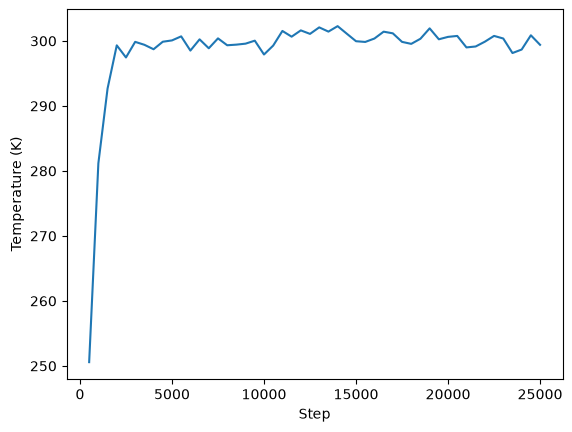

In [18]:
# Plotting the temperature over time
df = pd.read_csv(logfile, sep="\t")

plt.plot(df["Step"], df["Temperature (K)"])
plt.xlabel("Step")
plt.ylabel("Temperature (K)")
plt.show()

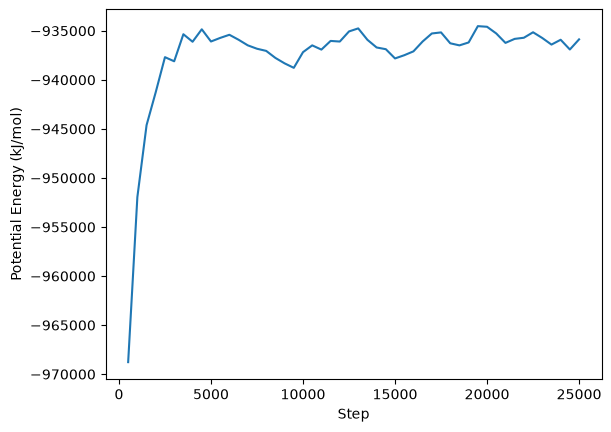

In [19]:
# Plotting the potential energy over time
plt.plot(df["Step"], df["Potential Energy (kJ/mole)"])
plt.xlabel("Step")
plt.ylabel("Potential Energy (kJ/mol)")
plt.show()

In [20]:
md_universe = mda.Universe(str(DATA / "topology.pdb"), str(DATA / "trajectory.xtc"))
view = nv.show_mdanalysis(md_universe)
view

/Users/bartrabelink/miniforge3/envs/acmdd/lib/python3.14/site-packages/MDAnalysis/topology/PDBParser.py:309: UserWarning: PDB file is missing resid information.  Defaulted to '1'
  warnings.warn("PDB file is missing resid information.  "
/Users/bartrabelink/miniforge3/envs/acmdd/lib/python3.14/site-packages/MDAnalysis/coordinates/XDR.py:261: UserWarning: Reload offsets from trajectory
 ctime or size or n_atoms did not match
  warnings.warn(


NGLWidget(max_frame=49)

In [21]:
# In case the above view does not allow for playing the movie, the play-button below 
# can be used to click through the trajectory and mimic the movie functionality
display(view._iplayer)

In [22]:
# Set trajectory pointer to first frame as reference
md_universe.trajectory[0]

# in_memory=True is needed to actually modify the loaded trajectory
# if the trajectory is too big for memory, one can write out the aligned trajectory and reload it into a new universe
alignment = align.AlignTraj(
    mobile=md_universe, reference=md_universe, select="protein", in_memory=True
)
alignment.run()

In [23]:
view = nv.show_mdanalysis(md_universe)
view

NGLWidget(max_frame=49)

In [24]:
# In case the above view does not allow for playing the movie, the play-button below 
# can be used to click through the trajectory and mimic the movie functionality
display(view._iplayer)

In [25]:
ligand_name = "LIG"  # the residue name we gave the docked ligand

In [26]:
def rmsd_for_atomgroups(universe, selection1, selection2=None):
    """Calulate the RMSD for selected atom groups.

    Parameters
    ----------
    universe: MDAnalysis.core.universe.Universe
        MDAnalysis universe.
    selection1: str
        Selection string for main atom group, also used during alignment.
    selection2: list of str, optional
        Selection strings for additional atom groups.

    Returns
    -------
    rmsd_df: pandas.core.frame.DataFrame
        DataFrame containing RMSD of the selected atom groups over time.
    """

    universe.trajectory[0]
    ref = universe
    rmsd_analysis = rms.RMSD(universe, ref, select=selection1, groupselections=selection2)
    rmsd_analysis.run()
    columns = [selection1, *selection2] if selection2 else [selection1]
    rmsd_df = pd.DataFrame(np.round(rmsd_analysis.rmsd[:, 2:], 2), columns=columns)
    rmsd_df.index.name = "frame"
    return rmsd_df

In [27]:
rmsd = rmsd_for_atomgroups(md_universe, "backbone", ["protein", f"resname {ligand_name}"])
rmsd.head()

/Users/bartrabelink/miniforge3/envs/acmdd/lib/python3.14/site-packages/MDAnalysis/analysis/rms.py:824: DeprecationWarning: The `rmsd` attribute was deprecated in MDAnalysis 2.0.0 and will be removed in MDAnalysis 3.0.0. Please use `results.rmsd` instead.
  warnings.warn(wmsg, DeprecationWarning)


,backbone,protein,resname LIG
frame,,,
0,0.00,0.00,0.00
1,0.65,0.88,1.10
2,0.71,0.99,1.14
3,0.75,1.06,1.30
4,0.89,1.19,1.95


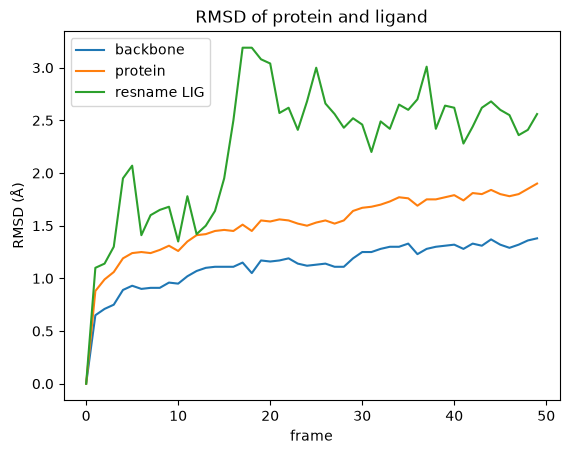

In [28]:
rmsd.plot(title="RMSD of protein and ligand")
plt.ylabel("RMSD (Å)");

In [29]:
def RMSD_dist_frames(universe, selection):
    """Calculate the RMSD between all frames in a matrix.

    Parameters
    ----------
    universe: MDAnalysis.core.universe.Universe
        MDAnalysis universe.
    selection: str
        Selection string for the atomgroup to be investigated, also used during alignment.

    Returns
    -------
    array: np.ndarray
        Numpy array of RMSD values.
    """
    pairwise_rmsd = diffusionmap.DistanceMatrix(universe, select=selection)
    pairwise_rmsd.run()
    return pairwise_rmsd.dist_matrix

In [30]:
dist_matrix_protein = RMSD_dist_frames(md_universe, "protein")
dist_matrix_ligand = RMSD_dist_frames(md_universe, f"resname {ligand_name}")

/Users/bartrabelink/miniforge3/envs/acmdd/lib/python3.14/site-packages/MDAnalysis/analysis/diffusionmap.py:297: DeprecationWarning: The `dist_matrix` attribute was deprecated in MDAnalysis 2.0.0 and will be removed in MDAnalysis 3.0.0. Please use `results.dist_matrix` instead.
  warnings.warn(wmsg, DeprecationWarning)


In [31]:
# get maximal distance between all frames
max_dist = max(np.amax(dist_matrix_ligand), np.amax(dist_matrix_protein))

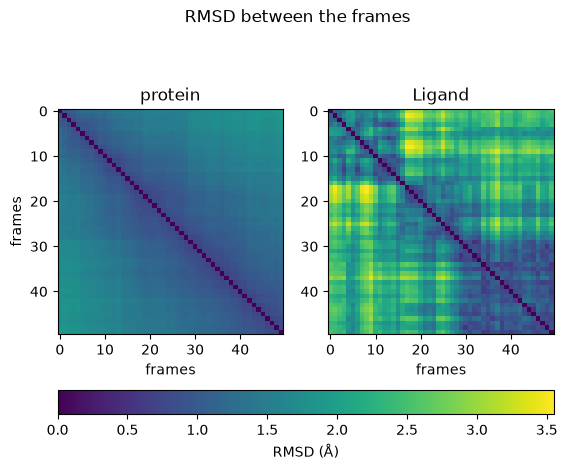

In [32]:
fig, ax = plt.subplots(1, 2)
fig.suptitle("RMSD between the frames")

# protein image
img1 = ax[0].imshow(dist_matrix_protein, cmap="viridis", vmin=0, vmax=max_dist)
ax[0].title.set_text("protein")
ax[0].set_xlabel("frames")
ax[0].set_ylabel("frames")

# ligand image
img2 = ax[1].imshow(dist_matrix_ligand, cmap="viridis", vmin=0, vmax=max_dist)
ax[1].title.set_text("Ligand")
ax[1].set_xlabel("frames")

fig.colorbar(img1, ax=ax, orientation="horizontal", fraction=0.1, label="RMSD (Å)")

In [33]:
# select pocket residues
pocket_resids = set(
    md_universe.select_atoms(f"(around 5 resname {ligand_name}) and protein").resids
)
view2 = nv.show_mdanalysis(md_universe)
view2.add_representation(
    "licorice", selection=f"protein and ({' '.join([str(x) for x in pocket_resids])})"
)
view2.center(selection="ligand")
view2

NGLWidget(max_frame=49)

In [34]:
# In case the above view does not allow for playing the movie, the play-button below 
# can be used to click through the trajectory and mimic the movie functionality
display(view2._iplayer)


In [35]:
# The key DRD2 contact: the salt bridge between the ligand's protonated piperazine
# nitrogen and Asp114. In the docked pose these sit 4.7 A apart, so this plot
# shows whether the interaction forms during the simulation.
protein_residue_id = "114"      # Asp114
protein_atom_name = "OD2"
ligand_id = "1"
ligand_atom_name = "N11"        # protonated piperazine nitrogen

In [36]:
atomgroup_protein = md_universe.select_atoms(
    f"resid {protein_residue_id} and name {protein_atom_name}"
)
atomgroup_ligand = md_universe.select_atoms(f"resname {ligand_name} and name {ligand_atom_name}")

In [37]:
# box=... applies the minimum-image convention. Without it the ligand may appear
# ~85 A away whenever it is wrapped to the other side of the periodic box.
distance = dist(atomgroup_protein, atomgroup_ligand, box=md_universe.dimensions)
print(
    f"The distance between residues {protein_residue_id} and {ligand_id} is {distance[2][0]:.2f} Å"
)

The distance between residues 114 and 1 is 3.59 Å


In [38]:
distances = []
for _ in md_universe.trajectory:
    distance = dist(atomgroup_protein, atomgroup_ligand, box=md_universe.dimensions)
    distances.append(distance[2][0])

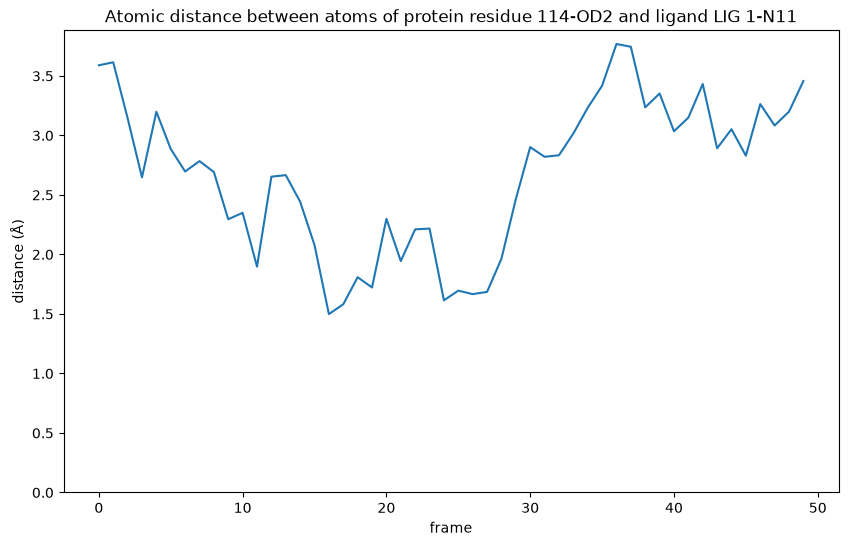

In [39]:
plt.figure(figsize=(10, 6))
plt.plot(distances)
plt.gca().set_ylim(bottom=0)
plt.ylabel("distance (Å)")
plt.xlabel("frame")
plt.title(f"Atomic distance between atoms of protein residue {protein_residue_id}-{protein_atom_name} and ligand {ligand_name} {ligand_id}-{ligand_atom_name}")
plt.show()

In [40]:
# A hydrogen bond needs a donor WITH a hydrogen. Asp114 is an acceptor (its
# carboxylate carries no H), so the pair followed above cannot be used here.
# The closest donor-acceptor pair in the docked pose is the Ser193 hydroxyl
# donating to the ligand's carbonyl oxygen (3.6 A in the starting structure).
donor_resid = "193"             # Ser193
donor_atom_name = "OG"
hydrogen_name = "HG"
acceptor_resid = "1"            # the ligand (resname LIG)
acceptor_atom_name = "O7"       # ligand carbonyl oxygen

In [41]:
def run_hydrogenbond_analysis(
    universe,
    donor_resid,
    donor_atom,
    hydrogen_atom,
    acceptor_resid,
    acceptor_atom,
    h_cutoff=1.2,
    a_cutoff=3.0,
    angle_cutoff=120,
):
    """
    Perform an hydrogen bond analysis between selcted atom groups.
    Return the data as readable, formatted data frame.

    Parameters
    ----------
    universe: MDAnalysis.core.universe.Universe
        MDAnalysis universe.
    donor_resid: str
        Residue Id of residue containing donor atom in MDAnalysis universe.
    donor_atom: str
        Name of the donor atom in the MDAnalysis universe.
    hydrogen_atom: str
        Name of involved hydrogen atom in the MDAnalysis universe.
    acceptor_resid: str
        Residue Id of residue containing acceptor atom in the MDAnalysis universe.
    acceptor_atom: str
        Name of the acceptor atom in the MDAnalysis universe.
    h_cutoff: float, optional
        Distance cutoff used for finding donor-hydrogen pairs.
    a_cutoff: float, optional
        Donor-acceptor distance cutoff for hydrogen bonds.
    angle_cutoff: int, optional
        D-H-A angle cutoff for hydrogen bonds.

    Returns
    -------
    bond : pandas.core.frame.DataFrame
        DataFrame containing hydrogen bond information over time.
    """

    # set up and run the hydrogen bond analysis (HBA)
    hbonds = HBA(
        universe=universe,
        donors_sel="resid " + donor_resid + " and name " + donor_atom,
        hydrogens_sel="resid " + donor_resid + " and name " + hydrogen_atom,
        acceptors_sel="resid " + acceptor_resid + " and name " + acceptor_atom,
        d_h_cutoff=h_cutoff,
        d_a_cutoff=a_cutoff,
        d_h_a_angle_cutoff=angle_cutoff,
    )
    hbonds.run()
    # extract bond data
    bond = pd.DataFrame(np.round(hbonds.hbonds, 2))
    # name columns (according to MDAnalysis function description)
    bond.columns = [
        "frame",
        "donor_index",
        "hydrogen_index",
        "acceptor_index",
        "distance",
        "angle",
    ]
    # set frame as the index
    bond["frame"] = bond["frame"].astype(int)
    bond.set_index("frame", inplace=True, drop=True)
    return bond

In [42]:
bond = run_hydrogenbond_analysis(
    md_universe, donor_resid, donor_atom_name, hydrogen_name, acceptor_resid, acceptor_atom_name
)
bond.head()

/Users/bartrabelink/miniforge3/envs/acmdd/lib/python3.14/site-packages/MDAnalysis/analysis/hydrogenbonds/hbond_analysis.py:747: UserWarning: No hydrogen bonds were found given d-a cutoff of 3.0 between Donor, resid 193 and name OG, and Acceptor, resid 1 and name O7.
  warnings.warn(
/Users/bartrabelink/miniforge3/envs/acmdd/lib/python3.14/site-packages/MDAnalysis/analysis/hydrogenbonds/hbond_analysis.py:779: UserWarning: No hydrogen bonds were found given angle of 120 between Donor, resid 193 and name OG, and Acceptor, resid 1 and name O7.
  warnings.warn(
/Users/bartrabelink/miniforge3/envs/acmdd/lib/python3.14/site-packages/MDAnalysis/analysis/hydrogenbonds/hbond_analysis.py:813: DeprecationWarning: The `hbonds` attribute was deprecated in MDAnalysis 2.0.0 and will be removed in MDAnalysis 3.0.0. Please use `results.hbonds` instead.
  warnings.warn(wmsg, DeprecationWarning)


,donor_index,hydrogen_index,acceptor_index,distance,angle
frame,,,,,
29,2526.0,2527.0,4381.0,2.78,173.18
30,2526.0,2527.0,4381.0,2.63,162.49
31,2526.0,2527.0,4381.0,2.69,154.91
32,2526.0,2527.0,4381.0,2.84,178.80
33,2526.0,2527.0,4381.0,2.75,165.18


In [43]:
bond = run_hydrogenbond_analysis(
    md_universe,
    donor_resid,
    donor_atom_name,
    hydrogen_name,
    acceptor_resid,
    acceptor_atom_name,
    a_cutoff=5.0,
)
bond.head()

/Users/bartrabelink/miniforge3/envs/acmdd/lib/python3.14/site-packages/MDAnalysis/analysis/hydrogenbonds/hbond_analysis.py:747: UserWarning: No hydrogen bonds were found given d-a cutoff of 5.0 between Donor, resid 193 and name OG, and Acceptor, resid 1 and name O7.
  warnings.warn(
/Users/bartrabelink/miniforge3/envs/acmdd/lib/python3.14/site-packages/MDAnalysis/analysis/hydrogenbonds/hbond_analysis.py:779: UserWarning: No hydrogen bonds were found given angle of 120 between Donor, resid 193 and name OG, and Acceptor, resid 1 and name O7.
  warnings.warn(
/Users/bartrabelink/miniforge3/envs/acmdd/lib/python3.14/site-packages/MDAnalysis/analysis/hydrogenbonds/hbond_analysis.py:813: DeprecationWarning: The `hbonds` attribute was deprecated in MDAnalysis 2.0.0 and will be removed in MDAnalysis 3.0.0. Please use `results.hbonds` instead.
  warnings.warn(wmsg, DeprecationWarning)


,donor_index,hydrogen_index,acceptor_index,distance,angle
frame,,,,,
17,2526.0,2527.0,4381.0,3.50,151.38
18,2526.0,2527.0,4381.0,3.87,146.78
19,2526.0,2527.0,4381.0,3.83,154.79
20,2526.0,2527.0,4381.0,3.40,164.25
21,2526.0,2527.0,4381.0,3.26,166.89


In [44]:
def plot_hydrogen_bond_over_time(bond):
    """
    Plot the distance and degree of a chosen hydrogen bond over time.
    Peaks in angle and dips in distance represent moments of strong binding.

    Parameters
    ----------
    bond: pandas.core.frame.DataFrame
        Hydrogen bond analysis data frame with named columns.
    """

    if bond.empty:
        print("No hydrogen bonds were found for this pair - nothing to plot.")
        return

    donor_index = bond.iloc[0].donor_index
    acceptor_index = bond.iloc[0].acceptor_index

    # add values for missing frames for gapless plotting
    bond = bond.reindex(np.arange(0, len(md_universe.trajectory)))

    # plot the data
    fig = plt.figure(figsize=(10, 6))
    distance = bond.distance.plot(
        title=f"Hydrogen bond between protein residue {donor_resid} and {ligand_name} ({acceptor_atom_name})",
        style="o-",
        x="frame",
    )
    distance.set_ylabel("distance (Å)")
    distance.set_xlabel("frame")
    distance.set_ylim(bottom=0)
    angle = bond.angle.plot(secondary_y=True, style="o-", x="frame")
    angle.set_ylabel("angle (°)")
    angle.set_xlabel("frame")
    angle.set_ylim(bottom=0)
    fig.legend(loc="lower right", bbox_to_anchor=(1, 0), bbox_transform=distance.transAxes)
    plt.show()

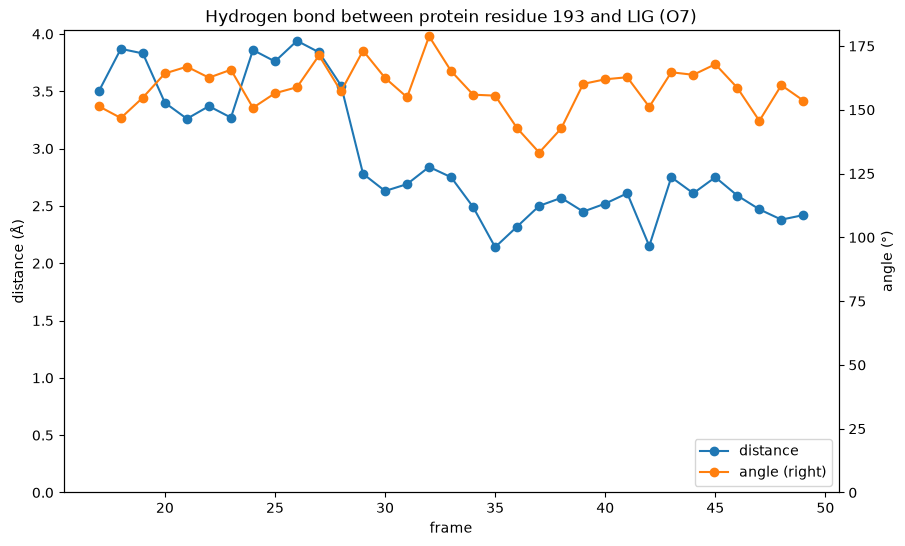

In [45]:
plot_hydrogen_bond_over_time(bond)

In [46]:
view_strong = nv.show_mdanalysis(md_universe)
view_strong.add_representation("ball+stick", selection=f"protein and {protein_residue_id}")
view_strong.center(selection="ligand")
# Frame where the Asp114 contact is closest
view_strong.frame = int(np.argmin(distances))
view_strong

NGLWidget(frame=16, max_frame=49)

In [47]:
# In case the above view does not allow for playing the movie, the play-button below 
# can be used to click through the trajectory and mimic the movie functionality
display(view_strong._iplayer)

In [48]:
view_bad = nv.show_mdanalysis(md_universe)
view_bad.add_representation("ball+stick", selection=f"protein and {protein_residue_id}")
view_bad.center(selection="ligand")
# Frame where the Asp114 contact is furthest
view_bad.frame = int(np.argmax(distances))
view_bad

NGLWidget(frame=36, max_frame=49)

In [49]:
# In case the above view does not allow for playing the movie, the play-button below 
# can be used to click through the trajectory and mimic the movie functionality
display(view_bad._iplayer)